<a href="https://colab.research.google.com/github/varsha-0110/Code-Station/blob/main/Stock_Price_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [51]:
ticker = "AAPL"
df = yf.download(ticker, '2020-01-01')


/tmp/ipykernel_1360/305499998.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, '2020-01-01')
[*********************100%***********************]  1 of 1 completed


In [52]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568932,72.326897,71.345153,71.501557,146322800
2020-01-06,72.139191,72.177691,70.442792,70.693043,118387200
2020-01-07,71.799911,72.403874,71.580942,72.148812,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200
...,...,...,...,...,...
2026-10-26,343.910004,347.089996,341.029999,343.920013,42743600
2026-10-27,347.100006,347.779999,342.390015,343.170013,39984400


<Axes: xlabel='Date'>

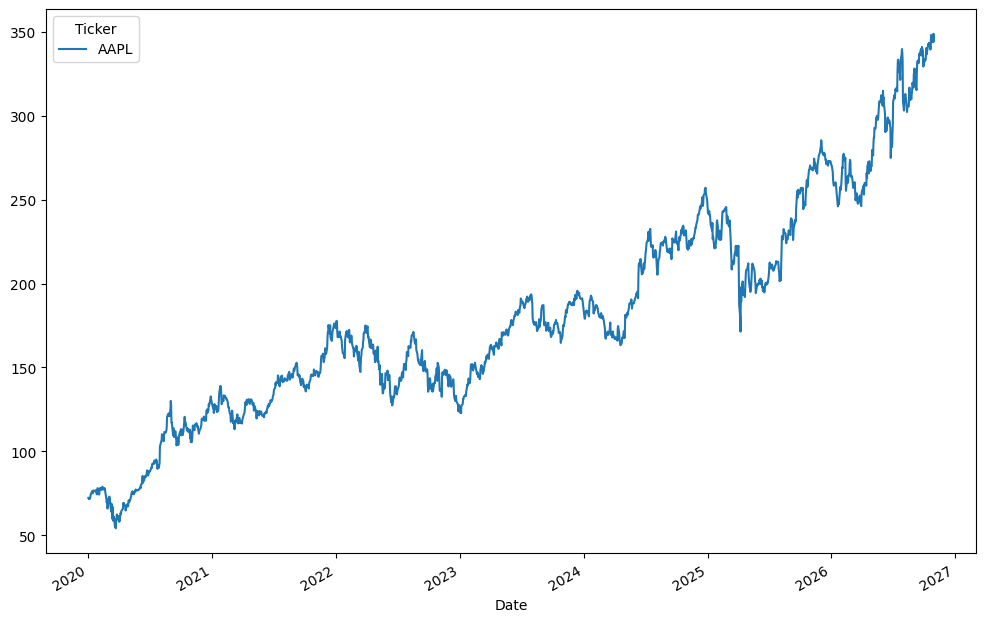

In [53]:
df.Close.plot(figsize = (12, 8))

In [54]:
scaler = StandardScaler()
df['Close'] = scaler.fit_transform(df['Close'])

In [55]:
df.Close

Ticker,AAPL
Date,
2020-01-02,-1.689555
2020-01-03,-1.700539
2020-01-06,-1.691624
2020-01-07,-1.696928
2020-01-08,-1.678873
...,...
2026-10-26,2.556791
2026-10-27,2.606658
2026-10-28,2.555540


In [56]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
  data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [57]:
data

array([[[-1.68955529],
        [-1.70053891],
        [-1.69162443],
        ...,
        [-1.61425521],
        [-1.58563749],
        [-1.59442246]],

       [[-1.70053891],
        [-1.69162443],
        [-1.69692816],
        ...,
        [-1.58563749],
        [-1.59442246],
        [-1.59412084]],

       [[-1.69162443],
        [-1.69692816],
        [-1.67887293],
        ...,
        [-1.59442246],
        [-1.59412084],
        [-1.616555  ]],

       ...,

       [[ 2.37701914],
        [ 2.44877156],
        [ 2.43517149],
        ...,
        [ 2.61650681],
        [ 2.55679113],
        [ 2.60665835]],

       [[ 2.44877156],
        [ 2.43517149],
        [ 2.47972378],
        ...,
        [ 2.55679113],
        [ 2.60665835],
        [ 2.55554028]],

       [[ 2.43517149],
        [ 2.47972378],
        [ 2.49176051],
        ...,
        [ 2.60665835],
        [ 2.55554028],
        [ 2.63495286]]])

In [58]:
train_size = int(0.8 * len(data))
X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [59]:
class PredictionModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
    super(PredictionModel, self).__init__()

    self.num_layers = num_layers
    self.hidden_dim = hidden_dim

    self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first = True)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)
    c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)

    out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
    out = self.fc(out[:, -1, :])

    return out

In [60]:
model = PredictionModel(input_dim = 1, hidden_dim = 32, num_layers = 2, output_dim = 1 ).to(device)

In [61]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)

In [62]:
class PredictionModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
    super(PredictionModel, self).__init__()

    self.num_layers = num_layers
    self.hidden_dim = hidden_dim

    self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first = True)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)
    c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)

    out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
    out = self.fc(out[:, -1, :])

    return out

# Ensure we have clean tensors for training and model definition
model = PredictionModel(input_dim = 1, hidden_dim = 32, num_layers = 2, output_dim = 1 ).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)

# Recreate X_train and y_train tensors in case they were modified/overwritten
train_size = int(0.8 * len(data))
X_train_tensor = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train_tensor = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)

num_epochs = 200
loss_history = []

for i in range(num_epochs):
  y_train_pred = model(X_train_tensor)

  loss = criterion(y_train_pred, y_train_tensor)
  loss_history.append(loss.item())
  if(i % 25 == 0):
    print(i, loss.item())

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

0 0.4999025762081146
25 0.014357030391693115
50 0.0049034180119633675
75 0.004221324343234301
100 0.003818509867414832
125 0.0035189150366932154
150 0.0032553214114159346
175 0.0030055996030569077


In [63]:
model.eval()
y_test_pred = model(X_test)

# Convert predictions and targets to numpy arrays only if they are PyTorch Tensors
y_train_pred_np = y_train_pred.detach().cpu().numpy() if isinstance(y_train_pred, torch.Tensor) else y_train_pred
y_train_np = y_train.detach().cpu().numpy() if isinstance(y_train, torch.Tensor) else y_train
y_test_pred_np = y_test_pred.detach().cpu().numpy() if isinstance(y_test_pred, torch.Tensor) else y_test_pred
y_test_np = y_test.detach().cpu().numpy() if isinstance(y_test, torch.Tensor) else y_test

# Inverse transform the values back to original prices
y_train_pred = scaler.inverse_transform(y_train_pred_np)
y_train = scaler.inverse_transform(y_train_np)
y_test_pred = scaler.inverse_transform(y_test_pred_np)
y_test = scaler.inverse_transform(y_test_np)

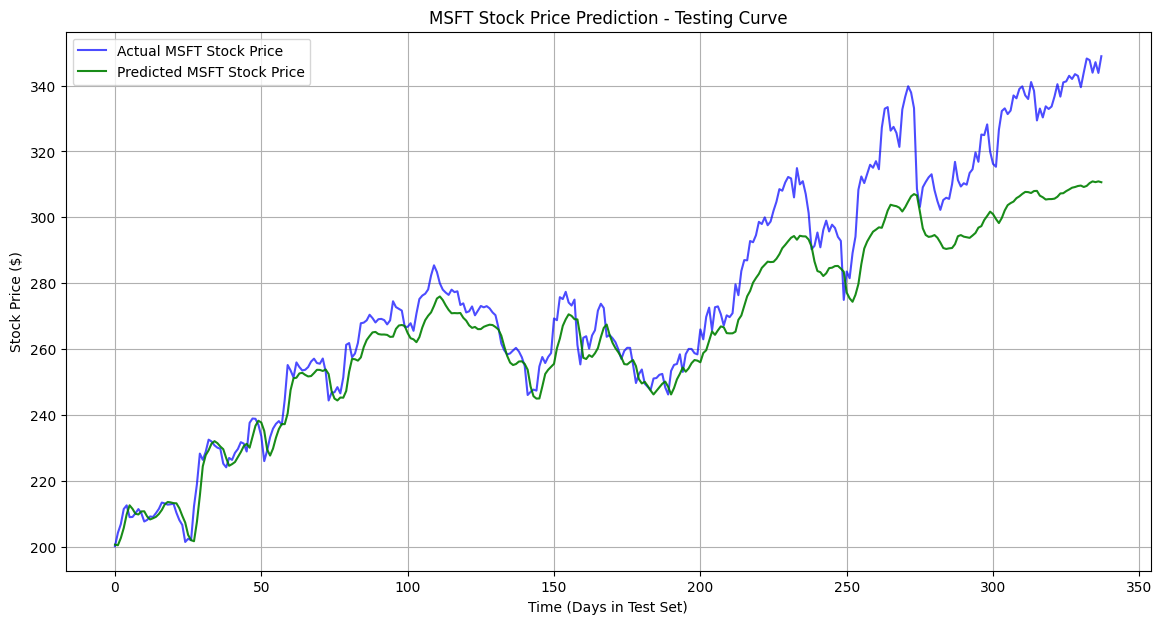

In [65]:
import matplotlib.pyplot as plt

# Create a plot to compare the actual and predicted testing prices
plt.figure(figsize=(14, 7))
plt.plot(y_test, label='Actual MSFT Stock Price', color='blue', alpha=0.7)
plt.plot(y_test_pred, label='Predicted MSFT Stock Price', color='green', alpha=0.9)
plt.title('MSFT Stock Price Prediction - Testing Curve')
plt.xlabel('Time (Days in Test Set)')
plt.ylabel('Stock Price ($)')
plt.legend()
plt.grid(True)
plt.show()

Train RMSE:  3.3658781758666474
Test RMSE:  14.694956862888317


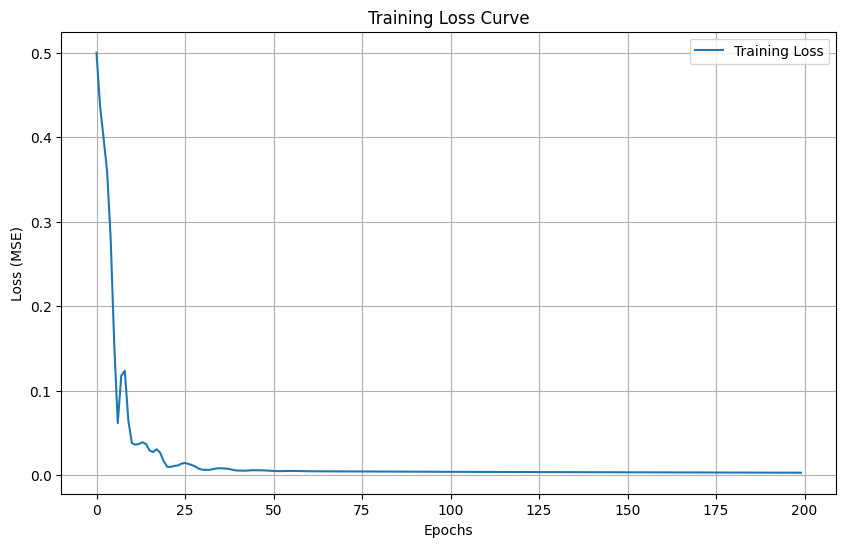

In [66]:
train_rmse = np.sqrt(mean_squared_error(y_train[:, 0], y_train_pred[:, 0]))
test_rmse = np.sqrt(mean_squared_error(y_test[:, 0], y_test_pred[:, 0]))

print("Train RMSE: ", train_rmse)
print("Test RMSE: ", test_rmse)

# Plot the training loss curve
plt.figure(figsize=(10, 6))
plt.plot(loss_history, label='Training Loss')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.grid(True)
plt.legend()
plt.show()

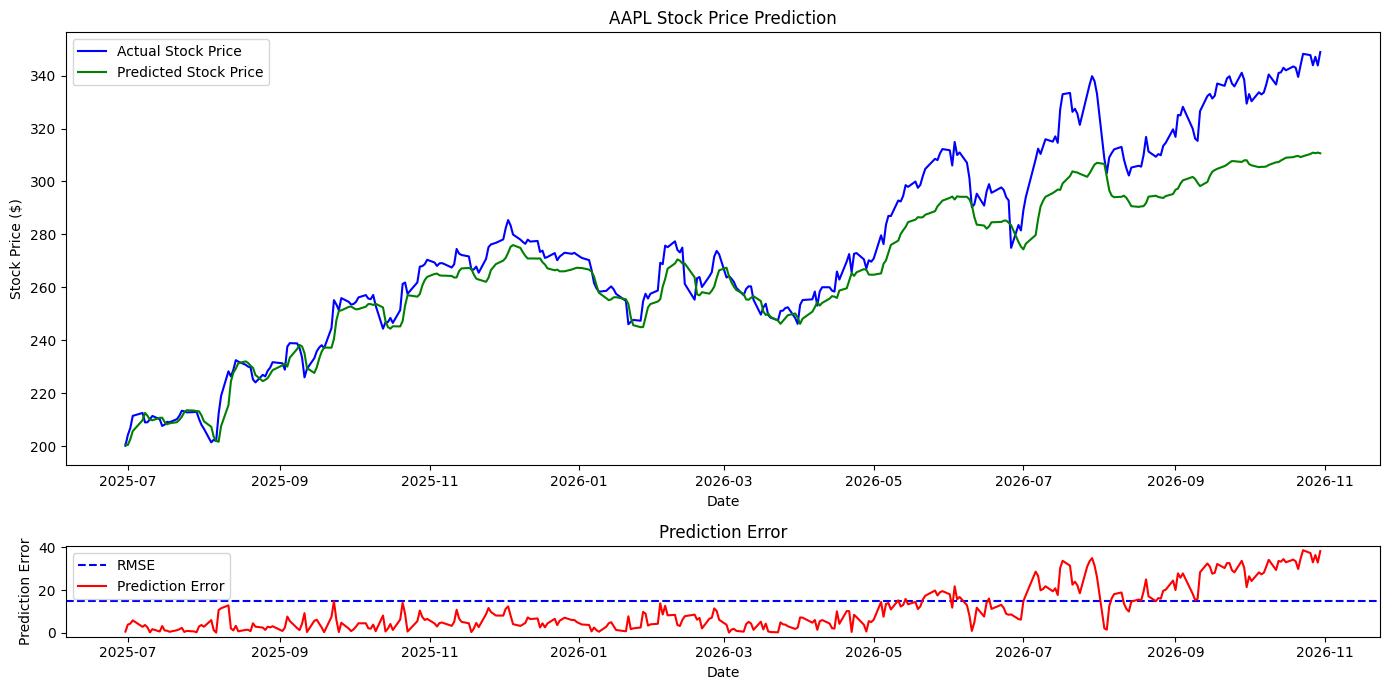

In [67]:
fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(4, 1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'Actual Stock Price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'Predicted Stock Price')

ax1.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel("Date")
plt.ylabel("Stock Price ($)")

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label = 'RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title("Prediction Error")
plt.xlabel("Date")
plt.ylabel("Prediction Error")

plt.tight_layout()
plt.show()